# **Знайомство з нейронними мережами**

Лабораторна робота №3, Семенков Олексій Фб-62мп

У цій лабораторній роботі досліджуються методи побудови та навчання нейронних мереж для різних типів даних: табличних даних, зображень і текстової інформації.

В межах першої частини роботи використовується датасет [Phishing Websites](https://https://archive.ics.uci.edu/dataset/327/phishing+websites), який застосовувався в лабораторній роботі №1. На його основі будується повнозв'язана нейронна мережа (MLP) за допомогою бібліотеки PyTorch. Досліджується процес навчання моделі, аналізуються криві втрат та оцінюється якість класифікації. Отримані результати порівнюються з класичними алгоритмами машинного навчання.

Друга частина лабораторної роботи присвячена класифікації зображень за допомогою згорткових нейронних мереж (CNN). Розглядається побудова власної архітектури CNN та використання попередньо натренованої моделі з подальшим донавчанням.

У третій частині досліджується класифікація текстових даних на основі датасету [BBC News Classification Dataset](https://https://huggingface.co/datasets/SetFit/bbc-news), який використовувався в лабораторній роботі №2. Для цього застосовуються рекурентні нейронні мережі з Embedding layer, а також попередньо натреновані векторні представлення слів.

### **1.1. Завантаження та підготовка датасету**

Для забезпечення коректного порівняння результатів нейронної мережі з класичними алгоритмами машинного навчання використовується аналогічний поділ даних на навчальну та тестову вибірки, як у попередній лабораторній роботі. Для цього застосовується `StratifiedGroupKFold`, який зберігає баланс класів і запобігає потраплянню однакових груп об'єктів до різних вибірок.

In [4]:
from ucimlrepo import fetch_ucirepo

phishing_websites = fetch_ucirepo(id=327)

X = phishing_websites.data.features.copy()
y = phishing_websites.data.targets.copy()

y = y.iloc[:, 0]

print("Розмір датасету:", X.shape)
print("Кількість ознак:", X.shape[1])

print("\nНазви ознак:")
print(X.columns.tolist())

print("\nПерші 5 записів:")
display(X.head())

print("\nРозподіл цільових класів:")
print(y.value_counts().sort_index())

print("\nТипи даних:")
print(X.dtypes.value_counts())

print("\nПропущені значення:")
print("Ознаки:", X.isnull().sum().sum())
print("Цільова змінна:", y.isnull().sum())

Розмір датасету: (11055, 30)
Кількість ознак: 30

Назви ознак:
['having_ip_address', 'url_length', 'shortining_service', 'having_at_symbol', 'double_slash_redirecting', 'prefix_suffix', 'having_sub_domain', 'sslfinal_state', 'domain_registration_length', 'favicon', 'port', 'https_token', 'request_url', 'url_of_anchor', 'links_in_tags', 'sfh', 'submitting_to_email', 'abnormal_url', 'redirect', 'on_mouseover', 'rightclick', 'popupwindow', 'iframe', 'age_of_domain', 'dnsrecord', 'web_traffic', 'page_rank', 'google_index', 'links_pointing_to_page', 'statistical_report']

Перші 5 записів:


,having_ip_address,url_length,shortining_service,having_at_symbol,double_slash_redirecting,prefix_suffix,having_sub_domain,sslfinal_state,domain_registration_length,favicon,...,rightclick,popupwindow,iframe,age_of_domain,dnsrecord,web_traffic,page_rank,google_index,links_pointing_to_page,statistical_report
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,1,-1,-1,-1,-1,1,1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,1,-1,-1,0,-1,1,1,1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,1,-1,1,-1,1,0,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,1,-1,-1,1,-1,1,-1,1
4,1,0,-1,1,1,-1,1,1,-1,1,...,1,-1,1,-1,-1,0,-1,1,1,1



Розподіл цільових класів:
result
-1    4898
 1    6157
Name: count, dtype: int64

Типи даних:
int64    30
Name: count, dtype: int64

Пропущені значення:
Ознаки: 0
Цільова змінна: 0


In [5]:
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

groups = X.groupby(list(X.columns), sort=False).ngroup().to_numpy()

# Перше розбиття: навчальна частина та тестова вибірка
outer_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_val_idx, test_idx = next(
    outer_cv.split(X, y_encoded, groups)
)

# Друге розбиття: навчальна та валідаційна вибірки
inner_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_rel_idx, val_rel_idx = next(
    inner_cv.split(
        X.iloc[train_val_idx],
        y_encoded[train_val_idx],
        groups[train_val_idx]
    )
)

train_idx = train_val_idx[train_rel_idx]
val_idx = train_val_idx[val_rel_idx]

# Формування вибірок
X_train = X.iloc[train_idx].to_numpy(dtype=np.float32)
X_val = X.iloc[val_idx].to_numpy(dtype=np.float32)
X_test = X.iloc[test_idx].to_numpy(dtype=np.float32)

y_train = y_encoded[train_idx].astype(np.int64)
y_val = y_encoded[val_idx].astype(np.int64)
y_test = y_encoded[test_idx].astype(np.int64)

# Масштабування ознак без витоку даних
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

print("Розміри вибірок:")
print(f"Навчальна:    {X_train.shape}")
print(f"Валідаційна:  {X_val.shape}")
print(f"Тестова:      {X_test.shape}")

print("\nРозподіл класів:")
for name, labels in [
    ("Навчальна", y_train),
    ("Валідаційна", y_val),
    ("Тестова", y_test)
]:
    counts = pd.Series(
        label_encoder.inverse_transform(labels)
    ).value_counts().sort_index()

    print(f"\n{name}:")
    print(counts)

train_groups = set(groups[train_idx])
val_groups = set(groups[val_idx])
test_groups = set(groups[test_idx])

print("\nПеревірка перетину груп:")
print("Train / Validation:", len(train_groups & val_groups))
print("Train / Test:", len(train_groups & test_groups))
print("Validation / Test:", len(val_groups & test_groups))

Розміри вибірок:
Навчальна:    (7035, 30)
Валідаційна:  (1806, 30)
Тестова:      (2214, 30)

Розподіл класів:

Навчальна:
-1    3132
 1    3903
Name: count, dtype: int64

Валідаційна:
-1     804
 1    1002
Name: count, dtype: int64

Тестова:
-1     962
 1    1252
Name: count, dtype: int64

Перевірка перетину груп:
Train / Validation: 0
Train / Test: 0
Validation / Test: 0


### **1.2. Побудова архітектури багатошарового перцептрона (MLP)**

Для класифікації фішингових вебсайтів використаємо MLP. Модель складатиметься з вхідного шару, двох прихованих повнозв'язних шарів і вихідного шару для прогнозування одного з двох класів.

У прихованих шарах застосуємо функцію активації ReLU та Dropout для зменшення ризику перенавчання. Вихідний шар повертатиме два значення — логіти для кожного класу. Для навчання використовуватимемо функцію втрат CrossEntropyLoss та оптимізатор Adam.

In [6]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Пристрій для навчання:", device)

# Перетворення даних у тензори PyTorch
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

batch_size = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

# Визначення архітектури MLP
class MLP(nn.Module):
    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.network(x)


model = MLP(input_size=X_train.shape[1]).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

print("\nАрхітектура моделі:")
print(model)

print("\nКількість параметрів моделі:",
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Пристрій для навчання: cpu

Архітектура моделі:
MLP(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=2, bias=True)
  )
)

Кількість параметрів моделі: 12354


### **1.3. Навчання нейронної мережі**

Навчання моделі здійснюється протягом декількох епох із використанням алгоритму Adam. На кожній епосі обчислюються значення функції втрат і точності для навчальної та валідаційної вибірок.

Для контролю перенавчання використовується механізм Early Stopping. Якщо значення валідаційних втрат не покращується протягом заданої кількості епох, навчання припиняється. При цьому зберігаються ваги моделі з найкращим результатом на валідаційній вибірці.

In [7]:
import copy

num_epochs = 100
patience = 10
best_val_loss = float("inf")
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

for epoch in range(num_epochs):

    # Режим навчання
    model.train()
    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for inputs, labels in train_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * inputs.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    model.eval()
    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            val_loss += loss.item() * inputs.size(0)

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    print(
        f"Епоха [{epoch + 1:03d}/{num_epochs}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Val Loss: {val_loss:.4f} "
        f"| Train Acc: {train_acc:.4f} "
        f"| Val Acc: {val_acc:.4f}"
    )

    # Перевірка покращення валідаційних втрат
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_weights = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print(f"\nEarly Stopping: навчання зупинено на епосі {epoch + 1}.")
        break

model.load_state_dict(best_model_weights)

print("\nНавчання завершено.")
print(f"Найкращі валідаційні втрати: {best_val_loss:.4f}")

Епоха [001/100] | Train Loss: 0.4041 | Val Loss: 0.2004 | Train Acc: 0.8399 | Val Acc: 0.9264
Епоха [002/100] | Train Loss: 0.1919 | Val Loss: 0.1688 | Train Acc: 0.9276 | Val Acc: 0.9308
Епоха [003/100] | Train Loss: 0.1695 | Val Loss: 0.1606 | Train Acc: 0.9336 | Val Acc: 0.9319
Епоха [004/100] | Train Loss: 0.1623 | Val Loss: 0.1596 | Train Acc: 0.9362 | Val Acc: 0.9347
Епоха [005/100] | Train Loss: 0.1528 | Val Loss: 0.1513 | Train Acc: 0.9407 | Val Acc: 0.9374
Епоха [006/100] | Train Loss: 0.1416 | Val Loss: 0.1499 | Train Acc: 0.9417 | Val Acc: 0.9413
Епоха [007/100] | Train Loss: 0.1395 | Val Loss: 0.1491 | Train Acc: 0.9427 | Val Acc: 0.9385
Епоха [008/100] | Train Loss: 0.1351 | Val Loss: 0.1471 | Train Acc: 0.9437 | Val Acc: 0.9352
Епоха [009/100] | Train Loss: 0.1248 | Val Loss: 0.1415 | Train Acc: 0.9485 | Val Acc: 0.9391
Епоха [010/100] | Train Loss: 0.1245 | Val Loss: 0.1384 | Train Acc: 0.9487 | Val Acc: 0.9396
Епоха [011/100] | Train Loss: 0.1160 | Val Loss: 0.1377 | Tr

### **1.4. Аналіз процесу навчання**

Для оцінювання динаміки навчання побудуємо графіки функції Loss та точності Accuracy на навчальній і валідаційній вибірках.

Графіки дадуть змогу простежити, як змінювалася якість моделі протягом епох, визначити момент стабілізації навчання та оцінити наявність перенавчання. Особливу увагу приділимо різниці між показниками на навчальній і валідаційній вибірках.

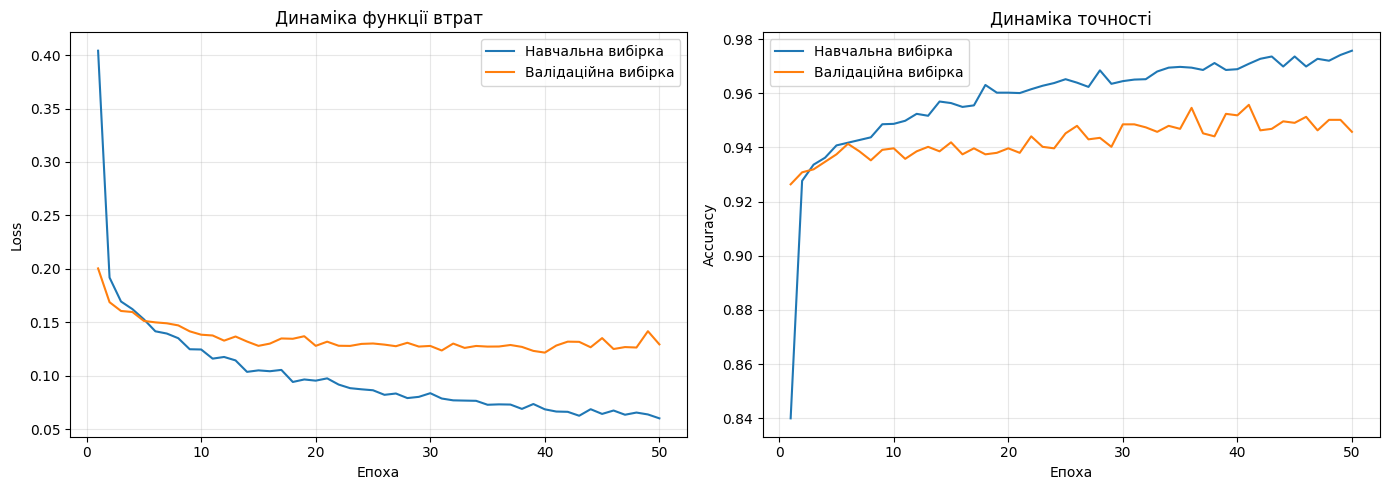

Найменші Validation Loss: 0.1216 (епоха 40)
Найбільша Validation Accuracy: 0.9557 (епоха 41)


In [8]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Графік функції втрат
axes[0].plot(epochs, history["train_loss"], label="Навчальна вибірка")
axes[0].plot(epochs, history["val_loss"], label="Валідаційна вибірка")
axes[0].set_title("Динаміка функції втрат")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Графік точності
axes[1].plot(epochs, history["train_acc"], label="Навчальна вибірка")
axes[1].plot(epochs, history["val_acc"], label="Валідаційна вибірка")
axes[1].set_title("Динаміка точності")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

best_val_loss_epoch = np.argmin(history["val_loss"]) + 1
best_val_acc_epoch = np.argmax(history["val_acc"]) + 1

print(f"Найменші Validation Loss: {min(history['val_loss']):.4f} "
      f"(епоха {best_val_loss_epoch})")

print(f"Найбільша Validation Accuracy: {max(history['val_acc']):.4f} "
      f"(епоха {best_val_acc_epoch})")

# **Аналіз графіків навчання.**

У процесі навчання спостерігається швидке зменшення функції втрат і зростання точності на обох вибірках. Після початкових епох навчання поступово стабілізується. Водночас навчальні втрати продовжують знижуватися, тоді як валідаційні втрати після певного моменту переважно коливаються без суттєвого покращення.

Навчальна точність наприкінці досягає приблизно 97,6%, тоді як найкраща валідаційна точність становить 95,57%. Така різниця свідчить про помірне перенавчання моделі. Використання Dropout та Early Stopping допомагає контролювати цей процес і зберегти параметри моделі з найкращими валідаційними втратами.

Mодель демонструє стабільне навчання та здатність узагальнювати закономірності даних, хоча наприкінці навчання спостерігається певне перенавчання.

### **1.5. Оцінювання якості моделі на тестовій вибірці**

Після завершення навчання оцінимо якість MLP на тестовій вибірці, яка не використовувалася під час оптимізації параметрів моделі. Для комплексного аналізу обчислимо Accuracy, Precision, Recall та F1-score, а також побудуємо Confusion Matrix.

Це дасть змогу оцінити здатність моделі правильно класифікувати фішингові та легітимні вебсайти на невідомих раніше даних.

Метрики якості MLP на тестовій вибірці:
Accuracy:  0.9481
Precision: 0.9471
Recall:    0.9472
F1-score:  0.9472

Звіт класифікації:
              precision    recall  f1-score   support

          -1     0.9398    0.9407    0.9403       962
           1     0.9544    0.9537    0.9541      1252

    accuracy                         0.9481      2214
   macro avg     0.9471    0.9472    0.9472      2214
weighted avg     0.9481    0.9481    0.9481      2214



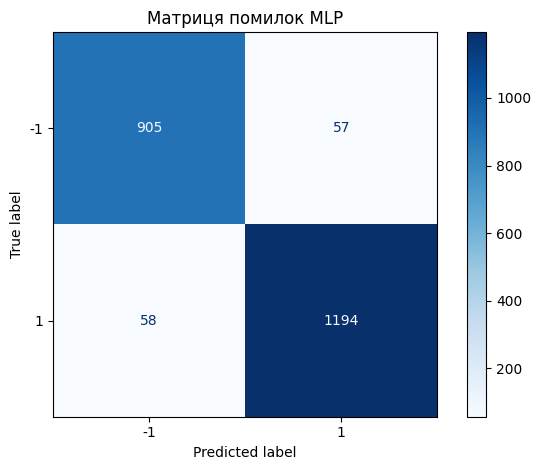

In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Переведення моделі в режим оцінювання
model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)

        outputs = model(inputs)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average="macro")
recall = recall_score(y_true, y_pred, average="macro")
f1 = f1_score(y_true, y_pred, average="macro")

print("Метрики якості MLP на тестовій вибірці:")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nЗвіт класифікації:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=[str(c) for c in label_encoder.classes_],
        digits=4
    )
)

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Матриця помилок MLP")
plt.tight_layout()
plt.show()

# **Аналіз результатів тестування.**

На тестовій вибірці модель MLP досягла Accuracy = 94,81%, Macro Precision = 94,71%, Macro Recall = 94,72% та Macro F1-score = 94,72%. Отримані результати свідчать про високу якість класифікації та здатність моделі узагальнювати закономірності, виявлені під час навчання.

Матриця помилок показує, що модель правильно класифікувала 905 записів класу -1 та 1194 записи класу 1. Водночас 57 записів першого класу було помилково віднесено до другого, а 58 записів другого класу — до першого.

Значення Precision, Recall та F1-score для обох класів є близькими, що свідчить про відсутність суттєвого перекосу моделі на користь одного з класів.

Отже, побудований багатошаровий перцептрон продемонстрував високу ефективність у задачі виявлення фішингових вебсайтів.

### **1.6. Порівняння MLP із класичними алгоритмами машинного навчання**

Для оцінювання ефективності нейронної мережі порівняємо її результати з класичними алгоритмами машинного навчання, дослідженими в першій лабораторній роботі: SVM, Random Forest, Decision Tree, AdaBoost та kNN.

За значенням Macro F1-score модель MLP отримала найкращий результат — 0,9472. Це дещо вище за показник SVM (0,9455) та Random Forest (0,9451). Також MLP продемонструвала найвище значення Accuracy — 0,9481.

Результати свідчать, що багатошаровий перцептрон здатний ефективно розв'язувати задачу класифікації фішингових вебсайтів і за отриманими метриками не поступається класичним алгоритмам. Водночас перевага над SVM та Random Forest є незначною.

Слід враховувати, що в першій і третій лабораторних роботах використовувалися тестові вибірки приблизно відповідного розміру (2 174 й 2 214 тестових записів відповідно), тому наведене порівняння має досить близький характер до фактичного.